# Benchmark: right-censored survival

Time-to-event data with censoring: for some subjects the event was observed,
for the others only that it had not happened by the end of follow-up. This
study compares how well each method ranks subjects by risk, how well its
predicted survival curves match what happened, and whether it recovers the
effect of each predictor, on two simulated tasks with 1,000 training and
3,000 test subjects and eight predictors of which three matter:

* **ph**: proportional hazards, the Cox model's assumption, with a Weibull
  baseline and log hazard ratio $0.8\sin 1.5x_1 + 0.5x_2 + 0.5[x_3 > 0]$;
* **aft**: a log-normal accelerated failure time model,
  $\log T = 1 + 0.6\sin 1.5x_1 + 0.4x_2 + 0.3[x_3 > 0] + 0.5\varepsilon$, in
  which hazards cross and the proportional-hazards assumption fails.

The term $0.5[x_3 > 0]$ is a step effect: the log hazard (or log time) jumps
by 0.5 where $x_3$ crosses 0 and is flat on either side.

About 35% of subjects are censored. mboostrs fits `CoxPH` and, on the
second task, `Lognormal` (a parametric accelerated failure time model).
`CoxPH` boosts the Cox partial likelihood, the likelihood of the observed
order of events, in which each event contributes the ratio of the event
subject's hazard to the summed hazard of everyone still at risk, so the
baseline hazard cancels. Each predictor enters as a `bbs` term (a P-spline,
a cubic B-spline basis with a penalty on differences of adjacent
coefficients), and `tune_mstop` chooses the number of boosting steps by
5-fold cross-validation. `gam_refit` refits the terms the boosted model
selected as a penalized additive Cox model with REML (restricted maximum
likelihood) smoothness selection and pointwise intervals. The competitors are the reference smooth Cox model (mgcv's `cox.ph`
family, REML), lifelines' Cox model, scikit-survival's random survival
forest, gradient-boosted Cox trees and componentwise linear Cox boosting, and
XGBoost's Cox objective; on the second task also lifelines' log-normal
accelerated failure time model (linear in the predictors) and XGBoost's
accelerated failure time objective. Results were measured with mboostrs
0.1.3.

:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | ranking of subjects by risk, calibration of predicted survival, and recovery of each predictor's effect on the log hazard |
| **Observed response** | simulated event or censoring time with an event indicator |
| **Estimand** | Harrell's C-index (the share of comparable pairs ordered correctly; higher is better); the integrated Brier score (IBS; lower is better), from the 10th to the 80th percentile of the training event times with inverse-probability-of-censoring weights; the error of the partial dependence of the log hazard against the true centred effect |
| **Units** | concordance probability; squared probability error; log hazard ratio |
| **Sampling unit** | one subject; 1,000 training and 3,000 test subjects per seed |
| **Dependence** | independent subjects |
| **Split / resampling unit** | a fresh test sample from the same design, its follow-up censored at the largest training time |
| **Tuning** | mboostrs: `tune_mstop` (5-fold CV); XGBoost: early stopping on a 20% validation split over depths 1-4; scikit-survival boosting: the number of trees on a 20% validation split; mgcv: REML; lifelines: ridge penalty 0.01; random survival forest: 500 trees, leaf size 10 |
| **Uncertainty** | mean and standard error over 8 seeds |
| **Claim type** | methodological |
:::

Harrell's C-index is the share of comparable pairs of test subjects (pairs
in which the subject with the shorter time had an observed event) that the
model orders correctly, with the higher predicted risk for the earlier
event; 0.5 is chance and 1 a perfect ordering. The integrated Brier score is
the squared difference between predicted survival probability and observed
survival status, averaged over the time range, with weights that correct for
censoring.

A Cox model gives a risk score, not a survival curve; the curve also needs
the cumulative baseline hazard. Every Cox-type method's survival curves are
built from its linear predictor with the same Breslow estimate of that
baseline (at each event time, the number of events divided by the summed
risk scores of the subjects still at risk, accumulated over time), so the integrated
Brier score compares risk scores and not each library's baseline estimator.
The random survival forest and the accelerated failure time models predict
survival curves directly. Test follow-up is censored at the largest training
time (0 to 8 of the 3,000 test subjects per seed), because the
inverse-censoring weights are estimated from the training data and are
undefined beyond its last observed time.

In [1]:
import json
from pathlib import Path

import altair as alt
import polars as pl

bench = json.loads(Path("bench_survival.json").read_text())
rows = [{k: v for k, v in r.items() if not isinstance(v, dict)}
        for r in bench["results"] if "error" not in r and "failure" not in r]
failed = [r for r in bench["results"] if "error" in r or "failure" in r]
survival = pl.from_dicts(rows, infer_schema_length=None, strict=False)
f"{survival.height} fits; {len(failed)} failed"

'152 fits; 0 failed'

In [2]:
table = (survival.group_by("task", "method")
         .agg(pl.len().alias("fits"), pl.col("cindex").mean(), (pl.col("cindex").std() / pl.len().sqrt()).alias("cindex se"),
              pl.col("ibs").mean(), pl.col("signal_effect_rmse").mean(),
              pl.col("noise_effect_sd").mean(), pl.col("seconds").mean())
         .sort("task", "cindex", descending=[False, True]))


def value(task, method, column):
    return float(table.filter((pl.col("task") == task) & (pl.col("method") == method))[column][0])

In [3]:
from great_tables import GT

from bench_tables import bold_best, shade_mboostrs

# One row per method, the two tasks side by side.
ph = table.filter(pl.col("task") == "ph").select(
    "method", pl.col("cindex").alias("ph_c"), pl.col("ibs").alias("ph_ibs"),
    pl.col("signal_effect_rmse").alias("ph_effect"),
    pl.col("noise_effect_sd").alias("ph_noise"))
aft = table.filter(pl.col("task") == "aft").select(
    "method", pl.col("cindex").alias("aft_c"), pl.col("ibs").alias("aft_ibs"),
    pl.col("seconds").alias("aft_s"))
seconds = table.group_by("method").agg(pl.col("seconds").mean())
wide = (aft.drop("aft_s").join(ph, on="method", how="left").join(seconds, on="method")
        .sort("aft_c", descending=True)
        .select("method", "ph_c", "ph_ibs", "ph_effect", "ph_noise", "aft_c", "aft_ibs",
                "seconds"))

In [4]:
survival_table = (
    GT(wide, rowname_col="method")
    .tab_header(title="Right-censored survival: every method on both tasks",
                subtitle="Mean over 8 simulated draws; 1,000 training and 3,000 test subjects per draw")
    .tab_stubhead("Method")
    .tab_spanner("Proportional hazards (ph)", ["ph_c", "ph_ibs", "ph_effect", "ph_noise"])
    .tab_spanner("Accelerated failure time (aft)", ["aft_c", "aft_ibs"])
    .cols_label(ph_c="C-index ↑", ph_ibs="IBS ↓", ph_effect="effect ↓",
                ph_noise="noise ↓", aft_c="C-index ↑", aft_ibs="IBS ↓", seconds="s")
    .fmt_number(columns="seconds", decimals=1)
    .sub_missing(missing_text="–")
)
survival_table = bold_best(survival_table, wide, {
    "ph_c": "max", "aft_c": "max", "ph_ibs": "min", "aft_ibs": "min",
    "ph_effect": "min", "ph_noise": "min"})

In [5]:
(shade_mboostrs(survival_table)
 .tab_source_note("C-index: Harrell's concordance of the risk score with the observed "
                  "times; 0.5 is chance, 1 is a perfect ordering. IBS: integrated Brier "
                  "score of the predicted survival curves from the 10th to the 80th "
                  "percentile of the training event times, inverse-censoring weighted.")
 .tab_source_note("Effect: root mean squared difference between each true "
                  "predictor's estimated partial effect on the log hazard and its true "
                  "centred effect, averaged over the three true predictors. Noise: "
                  "standard deviation of the partial effects given to the five irrelevant "
                  "predictors (0 is ideal). – : the method gives no partial effect or does "
                  "not fit that task. s: mean seconds per fit over "
                  "both tasks, including tuning and prediction.")
 .tab_source_note("Bold: best in the column. Rows are sorted by the aft C-index. Standard "
                  "errors of the mean C-index over draws are about 0.002 (ph) and 0.0016 "
                  "(aft), so differences below about 0.005 are not distinguishable; the "
                  "chart below shows each mean with two standard errors either side. Source: bench_survival.json."))

GT(_tbl_data=shape: (11, 8)
┌──────────────────┬──────────┬──────────┬───────────┬──────────┬──────────┬──────────┬────────────┐
│ method           ┆ ph_c     ┆ ph_ibs   ┆ ph_effect ┆ ph_noise ┆ aft_c    ┆ aft_ibs  ┆ seconds    │
│ ---              ┆ ---      ┆ ---      ┆ ---       ┆ ---      ┆ ---      ┆ ---      ┆ ---        │
│ str              ┆ f64      ┆ f64      ┆ f64       ┆ f64      ┆ f64      ┆ f64      ┆ f64        │
╞══════════════════╪══════════╪══════════╪═══════════╪══════════╪══════════╪══════════╪════════════╡
│ mboostrs         ┆ null     ┆ null     ┆ null      ┆ null     ┆ 0.804212 ┆ 0.124788 ┆ 1.420795   │
│ Lognormal AFT    ┆          ┆          ┆           ┆          ┆          ┆          ┆            │
│ mboostrs CoxPH   ┆ 0.694411 ┆ 0.171    ┆ 0.090465  ┆ 0.021178 ┆ 0.803242 ┆ 0.127197 ┆ 0.993083   │
│ mboostrs CoxPH + ┆ 0.693002 ┆ 0.171467 ┆ 0.083423  ┆ 0.033354 ┆ 0.802858 ┆ 0.1265   ┆ 4.74916    │
│ REML refit       ┆          ┆          ┆           ┆          ┆          ┆          ┆            │
│ mgcv Cox GAM     ┆ 0.692633 ┆ 0.171579 ┆ 0.08296   ┆ 0.043144 ┆ 0.802574 ┆ 0.126629 ┆ 25.723145  │
│ XGBoost AFT      ┆ null     ┆ null     ┆ null      ┆ null     ┆ 0.801137 ┆ 0.126931 ┆ 2.98859    │
│ …                ┆ …        ┆ …        ┆ …         ┆ …        ┆ …        ┆ …        ┆ …          │
│ sksurv           ┆ 0.686205 ┆ 0.174558 ┆ 0.112194  ┆ 0.032675 ┆ 0.799235 ┆ 0.129539 ┆ 54.476404  │
│ gradient-boosted ┆          ┆          ┆           ┆          ┆          ┆          ┆            │
│ Cox tr…          ┆          ┆          ┆           ┆          ┆          ┆          ┆            │
│ sksurv random    ┆ 0.686661 ┆ 0.174967 ┆ null      ┆ null     ┆ 0.796006 ┆ 0.133717 ┆ 403.990441 │
│ survival forest  ┆          ┆          ┆           ┆          ┆          ┆          ┆            │
│ sksurv           ┆ 0.691168 ┆ 0.1726   ┆ 0.126333  ┆ 0.016218 ┆ 0.795761 ┆ 0.132089 ┆ 54.489475  │
│ componentwise    ┆          ┆          ┆           ┆          ┆          ┆          ┆            │
│ Cox boost…       ┆          ┆          ┆           ┆          ┆          ┆          ┆            │
│ lifelines        ┆ null     ┆ null     ┆ null      ┆ null     ┆ 0.795646 ┆ 0.128821 ┆ 0.927327   │
│ log-normal AFT   ┆          ┆          ┆           ┆          ┆          ┆          ┆            │
│ lifelines Cox    ┆ 0.691206 ┆ 0.17236  ┆ 0.109984  ┆ 0.031591 ┆ 0.794833 ┆ 0.130851 ┆ 0.426304   │
└──────────────────┴──────────┴──────────┴───────────┴──────────┴──────────┴──────────┴────────────┘, _body=<great_tables._gt_data.Body object at 0x1115aaf60>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None, stub_level=0), ColInfo(var='ph_c', type=<ColInfoTypeEnum.default: 1>, column_label='C-index ↑', column_align='right', column_width=None, stub_level=None), ColInfo(var='ph_ibs', type=<ColInfoTypeEnum.default: 1>, column_label='IBS ↓', column_align='right', column_width=None, stub_level=None), ColInfo(var='ph_effect', type=<ColInfoTypeEnum.default: 1>, column_label='effect ↓', column_align='right', column_width=None, stub_level=None), ColInfo(var='ph_noise', type=<ColInfoTypeEnum.default: 1>, column_label='noise ↓', column_align='right', column_width=None, stub_level=None), ColInfo(var='aft_c', type=<ColInfoTypeEnum.default: 1>, column_label='C-index ↑', column_align='right', column_width=None, stub_level=None), ColInfo(var='aft_ibs', type=<ColInfoTypeEnum.default: 1>, column_label='IBS ↓', column_align='right', column_width=None, stub_level=None), ColInfo(var='seconds', type=<ColInfoTypeEnum.default: 1>, column_label='s', column_align='right', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x10addb4a0>, _spanners=Spanners([SpannerInfo(spanner_id='Proportional hazards (ph)', spanner_level=0, spanner_label='Proportional hazards (ph)', spanner_units=None, spanner_pattern=None, vars=['ph_c', 'ph_ibs', '

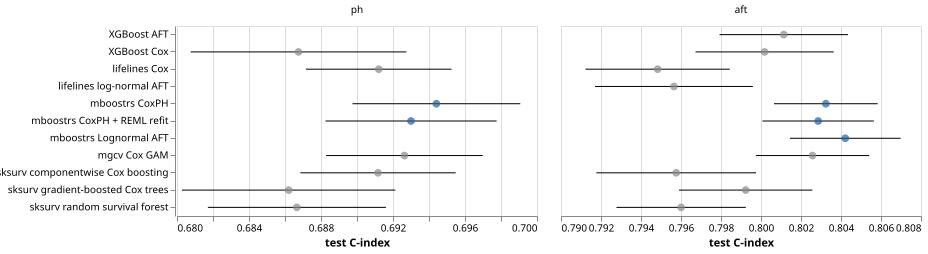

In [6]:
chart_data = table.with_columns(
    (pl.col("cindex") - 2 * pl.col("cindex se")).alias("low"),
    (pl.col("cindex") + 2 * pl.col("cindex se")).alias("high"),
    pl.col("method").str.starts_with("mboostrs").alias("mboostrs"))
base = alt.Chart(chart_data).encode(y=alt.Y("method:N", sort="-x", title=None))
display((base.mark_rule().encode(x=alt.X("low:Q", title="test C-index", scale=alt.Scale(zero=False)),
                                 x2="high:Q")
         + base.mark_point(filled=True, size=60).encode(
             x="cindex:Q", color=alt.Color("mboostrs:N", legend=None,
                                           scale=alt.Scale(range=["#8a8a8a", "#1f5fa8"]))))
        .properties(width=360, height=190)
        .facet(column=alt.Column("task:N", title=None, sort=["ph", "aft"]))
        .resolve_scale(x="independent"))

## Results

All 152 fits completed. With proportional hazards, mboostrs' `CoxPH` has
the highest mean C-index,
{eval}`round(value("ph", "mboostrs CoxPH", "cindex"), 4)`, and the lowest
integrated Brier score, {eval}`round(value("ph", "mboostrs CoxPH", "ibs"), 4)`;
its REML refit and mgcv's Cox GAM follow at
{eval}`round(value("ph", "mboostrs CoxPH + REML refit", "cindex"), 4)` and
{eval}`round(value("ph", "mgcv Cox GAM", "cindex"), 4)`.
The differences between methods in C-index are small: the whole range of
mean C-indices is about 0.008, three to four standard errors of one method's
mean.

The differences in the recovered effects are larger. mgcv and the REML
refit of the boosted model recover the true log-hazard curves most closely
(error {eval}`round(value("ph", "mgcv Cox GAM", "signal_effect_rmse"), 3)` and
{eval}`round(value("ph", "mboostrs CoxPH + REML refit", "signal_effect_rmse"), 3)`),
boosted `CoxPH` is next ({eval}`round(value("ph", "mboostrs CoxPH", "signal_effect_rmse"), 3)`),
and the linear Cox model and the tree methods have errors between
{eval}`round(min(value("ph", m, "signal_effect_rmse") for m in ("lifelines Cox", "XGBoost Cox", "sksurv gradient-boosted Cox trees", "sksurv componentwise Cox boosting")), 3)`
and
{eval}`round(max(value("ph", m, "signal_effect_rmse") for m in ("lifelines Cox", "XGBoost Cox", "sksurv gradient-boosted Cox trees", "sksurv componentwise Cox boosting")), 3)`,
about a third larger than mgcv's. mboostrs gives the five irrelevant
predictors less spurious effect than mgcv (their partial-dependence spread
is {eval}`round(value("ph", "mboostrs CoxPH", "noise_effect_sd"), 3)` against
{eval}`round(value("ph", "mgcv Cox GAM", "noise_effect_sd"), 3)`), and it takes
{eval}`round(value("ph", "mboostrs CoxPH", "seconds"), 1)` seconds per fit with
tuning, against {eval}`round(value("ph", "mgcv Cox GAM", "seconds"), 1)` for mgcv
and {eval}`round(value("ph", "sksurv random survival forest", "seconds"))` for
the random survival forest.

When the hazards are not proportional, the parametric model that matches the
truth, mboostrs' `Lognormal`, is best on both measures (C-index
{eval}`round(value("aft", "mboostrs Lognormal AFT", "cindex"), 4)`, IBS
{eval}`round(value("aft", "mboostrs Lognormal AFT", "ibs"), 4)`); among the Cox
models mboostrs is first ({eval}`round(value("aft", "mboostrs CoxPH", "cindex"), 4)`).
XGBoost's accelerated failure time objective is next among the
non-mboostrs methods
({eval}`round(value("aft", "XGBoost AFT", "cindex"), 4)`). lifelines'
log-normal model has the correct distribution but a linear effect of $x_1$
where the truth is a sine, and scores
{eval}`round(value("aft", "lifelines log-normal AFT", "cindex"), 4)`, level with
the linear Cox models. It differs from mboostrs' `Lognormal` in the effects
(linear against `bbs` smooths) and in the estimator (maximum likelihood
against early-stopped boosting). The gap of
{eval}`round(value("aft", "mboostrs Lognormal AFT", "cindex") - value("aft", "lifelines log-normal AFT", "cindex"), 4)`
comes from the effects: in a separate run on the same eight draws, boosted
`Lognormal` with linear `bols` terms in place of the smooths scored a
C-index of 0.7962, level with lifelines. The random survival forest, which
assumes no hazard shape, is below the smooth Cox models and the parametric
model (C-index
{eval}`round(value("aft", "sksurv random survival forest", "cindex"), 4)`) and
level with the linear models.

## The REML refit of a Cox model

`gam_refit` accepts boosted Cox models and returns REML-smoothed effects
with pointwise intervals, as mgcv's `cox.ph` family does. A Cox model with
Breslow's baseline hazard has the same likelihood as a Poisson model for the
event indicator with the log cumulative baseline hazard as offset. The refit
therefore alternates two steps until the fit stops moving: a Breslow update
of the baseline, and a penalized Poisson fit whose smoothing parameters
minimize the REML criterion, evaluated with a Laplace approximation to the
integral over the coefficients ([](../methodology/penalized_reml.ipynb) §10).

The refitted effects are as close to the truth as mgcv's
({eval}`round(value("ph", "mboostrs CoxPH + REML refit", "signal_effect_rmse"), 3)`
against {eval}`round(value("ph", "mgcv Cox GAM", "signal_effect_rmse"), 3)`),
and on the first seed its effective degrees of freedom match mgcv's for seven
of the eight terms (5.5 for $x_1$ in both). For the step effect of $x_3$ the
refit chooses 1.0 and mgcv 2.6. mgcv minimizes its REML score, so lower is
better, and the criterion has two local minima for this term. mgcv's score
is 3742.703 at its reported fit and 3742.642 at the refit's smoothing
parameters, so mgcv's default search stops at the worse of the two minima;
started from the refit's smoothing parameters, mgcv returns the refit's
degrees of freedom.

## Summary

On eight proportional-hazards draws, boosted `CoxPH` has the
highest mean C-index and lowest mean integrated Brier score; mgcv and the
REML refit have the smallest mean effect errors. On eight
accelerated-failure-time draws, the correctly specified `Lognormal` model
leads on both prediction measures, ahead of XGBoost's AFT objective and of
lifelines' linear log-normal model. The range of mean C-indices among the
Cox models, about 0.008, is close to the seed-to-seed standard deviation of
a single method's C-index (0.004 to 0.008), so the ranking by C-index is
weak evidence; the effect errors separate the methods more clearly.

## Limitations

Censoring is independent of the predictors and the effects are additive; a
design with covariate-dependent censoring or interactions in the hazard would
test the methods differently. The C-index differences are small enough that
their ordering can change with the seed.

## Reproduction

The page reads `bench_survival.json`, which stores one record per task,
method and seed (8 seeds, 1,000 training and 3,000 test subjects, 8
predictors), the tuning protocol and the library versions.